## Notebook de Avaliação dos experimentos feitos em outubro de 2026

Experimentos de segmentação via DCA UNet

1. primeiro modelo:
- 50 épocas
- loss : Cross-entropy sem peso

2. segundo modelo:
- 100 épocas
- loss: Cross-entropy com peso + dice loss

In [1]:
import os
import random
from glob import glob
import copy

import math

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import albumentations as A

import tensorflow as tf
import keras

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms

configurações de usuário

In [2]:
# ------------------------
USUARIO = 'vinicius'
# ------------------------


# Detecta se está rodando no Google Colab
IN_COLAB = "COLAB_RELEASE_TAG" in os.environ

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = r"/content/drive/MyDrive/wag-segmentation/outubro_2026"
else:
    if USUARIO == 'vinicius':
        BASE_DIR = r'C:\labmems\wag-segment\data\out_segmentation'
    elif USUARIO == 'ramon':
        BASE_DIR = r'C:\Users\Master\Desktop\wag-segmentation-main\data\out_segmentation'

print(f"Ambiente: {'Google Colab' if IN_COLAB else 'Local'}")
print(f"Diretório base: {BASE_DIR}")


Mounted at /content/drive
Ambiente: Google Colab
Diretório base: /content/drive/MyDrive/wag-segmentation/outubro_2026


In [8]:
AUGMENTED_DIR = os.path.join(BASE_DIR, 'augmented')

NOME_ORIGINAL = 'outubro_2026_original.png'
NOME_CORTADO  = 'out_2026.png'

PASTA_MODELOS = os.path.join(BASE_DIR, 'models')
os.makedirs(PASTA_MODELOS, exist_ok=True)

input_save_dir = os.path.join(AUGMENTED_DIR, 'input')
label_save_dir = os.path.join(AUGMENTED_DIR, 'label')

Definição do dataset

In [9]:
NUM_IMAGENS = 750   # num de imagens aumentadas
HEIGHT = 776       # altura final das imagens aumentadas
WIDTH = 1400       # largura final das imagens aumentadas
SEED = 42

In [10]:
COR_PARA_CLASSE = {
    (255, 255, 25): 0,  # MiMo: amarelo
    (0, 170, 255): 1,   # Água: azul
    (170, 0, 0): 2,     # Óleo: vermelho
    (0, 170, 0): 3,     # Gás: verde
}

In [11]:
class WagDataset(torch.utils.data.Dataset):
    def __init__(self, img_dir, label_dir, train, train_percent=0.8, transform=None):
        self.img_dir = img_dir
        self.label_dir = label_dir

        self.train_percent = train_percent


        # split de treino e validação
        if train:
            self.imgs_names = os.listdir(img_dir)[:int(len(os.listdir(img_dir)) * self.train_percent)]
            self.masks_names = os.listdir(label_dir)[:int(len(os.listdir(label_dir)) * self.train_percent)]
        else:
            self.imgs_names = os.listdir(img_dir)[int(len(os.listdir(img_dir)) * self.train_percent):]
            self.masks_names = os.listdir(label_dir)[int(len(os.listdir(label_dir)) * self.train_percent):]

        self.color_map = COR_PARA_CLASSE

        # transformador de imagem para tensor
        if transform == None:
            self.transform = transforms.ToTensor()
        else:
            self.transform = transform

    def _mask_to_classes(self, mask: np.ndarray):
        """
        Converte a representação RGB da máscara para uma classe numérica
        a ser usada na classe `nn.CrossEntropyLoss()` para fazer gradiente
        descendente no modelo.

        Parametros
        ----------
        mask : np.ndarray
            Shape [H, W, 3], tipicamente em dtype uint8.

        Retorna
        -------
        np.ndarray
            Shape [H, W], dtype int64, containing class IDs.
        """

        # [C, 3]
        colors = np.array(
            list(self.color_map.keys()),
            dtype=np.float32
        )

        # [C]
        class_ids = np.array(
            list(self.color_map.values()),
            dtype=np.int64
        )

        # [H, W, 3] -> [H, W, 1, 3]
        pixels = mask.astype(np.float32)[..., None, :]

        # Broadcasting:
        #
        # pixels: [H, W, 1, 3]
        # colors:          [C, 3]
        #
        # result: [H, W, C]
        distances_sq = np.sum(
            (pixels - colors) ** 2,
            axis=-1
        )

        # For every pixel, find nearest color.
        # [H, W, C] -> [H, W]
        nearest = np.argmin(distances_sq, axis=-1)

        # Convert color index -> actual class ID
        target = class_ids[nearest]

        return target

    def class_to_mask(self, probs: torch.Tensor) -> np.ndarray:
        """
        Converte probabilidades previstas pelo modelo em máscaras RGB.

        Parametros
        ----------
        probs : torch.Tensor
            Shape [B, C, H, W], em float32.

        Retorna
        -------
        np.ndarray
            Shape [B, H, W, 3], dtype int64, contendo as cores
            originais de cada classe de acordo com self.color_map.
        """

        # [B, C, H, W] -> [B, H, W]
        # Seleciona a classe mais provável para cada pixel.
        classes = probs.argmax(dim=1).cpu().numpy()

        # Inverte o mapeamento RGB -> classe para classe -> RGB.
        # [C, 3]
        colors = np.empty((probs.shape[1], 3), dtype=np.int64)

        for rgb, class_id in self.color_map.items():
            colors[class_id] = rgb

        # [B, H, W] -> [B, H, W, 3]
        mask = colors[classes]

        return mask


    def __len__(self):
        assert len(self.imgs_names) == len(self.masks_names)
        return len(self.imgs_names)

    def __getitem__(self, idx):

        img = Image.open(os.path.join(self.img_dir, self.imgs_names[idx]))
        mask = Image.open(os.path.join(self.label_dir, self.masks_names[idx]))

        # converter imagem para tensor
        img = self.transform(img)

        # converter mascara para tensor
        mask = np.asarray(mask)
        mask = self._mask_to_classes(mask)
        mask = torch.from_numpy(mask).long()

        return img, mask


In [12]:
train_dataset = WagDataset(input_save_dir, label_save_dir, train=True)
val_dataset = WagDataset(input_save_dir, label_save_dir, train=False)

print(f"Verificando instancia do dataset.")
print("-----------------------------------")
print(f"Tamanho do treino: {len(train_dataset)} amostras.")
print(f"Tamanho do treino: {len(val_dataset)} amostras.")

img, mask = train_dataset[0]
print(f"Shape da imagem: {img.shape}")
print(f"Shape da máscara: {mask.shape}")

print("-----------------------------------")
print(f"Amostra de imagem e máscara numericamente")
print(img)
print(mask)
print("-----------------------------------")

Verificando instancia do dataset.
-----------------------------------
Tamanho do treino: 600 amostras.
Tamanho do treino: 150 amostras.
Shape da imagem: torch.Size([3, 776, 1400])
Shape da máscara: torch.Size([776, 1400])
-----------------------------------
Amostra de imagem e máscara numericamente
tensor([[[0.5804, 0.5961, 0.6118,  ..., 0.6745, 0.6745, 0.6706],
         [0.5647, 0.5804, 0.6000,  ..., 0.6745, 0.6745, 0.6745],
         [0.5490, 0.5647, 0.5843,  ..., 0.6745, 0.6745, 0.6745],
         ...,
         [0.6627, 0.6627, 0.6627,  ..., 0.3294, 0.3294, 0.3294],
         [0.6471, 0.6471, 0.6471,  ..., 0.3294, 0.3294, 0.3294],
         [0.6471, 0.6471, 0.6471,  ..., 0.3294, 0.3294, 0.3294]],

        [[0.6353, 0.6549, 0.6745,  ..., 0.7255, 0.7255, 0.7216],
         [0.6157, 0.6353, 0.6549,  ..., 0.7255, 0.7255, 0.7255],
         [0.5961, 0.6118, 0.6314,  ..., 0.7294, 0.7294, 0.7294],
         ...,
         [0.7020, 0.7059, 0.7059,  ..., 0.1569, 0.1569, 0.1569],
         [0.6863, 0.

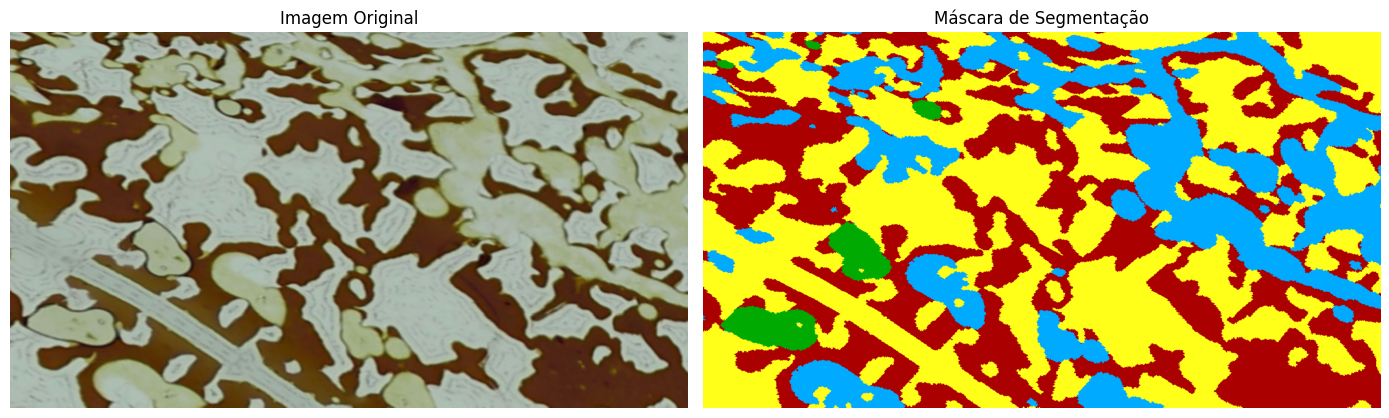

In [13]:
# visualização do mapeamento de classes

# [C, H, W] -> [H, W, C]
img_rgb = img.permute(1, 2, 0).cpu().numpy()

# [H, W] -> [H, W, C] -> [1, C, H, W]
num_classes = len(train_dataset.color_map)

# simulando output de rede neural}
mask_probs = F.one_hot(
    mask.long(),
    num_classes=num_classes
).permute(2, 0, 1).unsqueeze(0).float()

# [1, C, H, W] -> [1, H, W, 3] -> [H, W, 3]
mask_rgb = train_dataset.class_to_mask(mask_probs)[0]

# Plotar
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(img_rgb)
axes[0].set_title("Imagem Original")
axes[0].axis("off")

axes[1].imshow(mask_rgb.astype("uint8"))
axes[1].set_title("Máscara de Segmentação")
axes[1].axis("off")

plt.tight_layout()
plt.show()

Inferência com os modelos

In [16]:
# pegar device (cpu ou cuda)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [17]:
class RoPE(nn.Module):
    def __init__(self, sequence_len, embedding_dim):
        super(RoPE, self).__init__()

        self.sequence_len = sequence_len
        self.embedding_dim = embedding_dim

        pos_vec = torch.arange(0, sequence_len, 1, dtype=torch.float32)
        dims_vec = torch.arange(0, embedding_dim//2, 1, dtype=torch.float32)

        unity = torch.ones([sequence_len, embedding_dim//2])
        pos = pos_vec.reshape(sequence_len, 1) * unity
        dims = dims_vec.reshape(1, embedding_dim//2) * unity

        theta = pos / 10000**(2 * dims / embedding_dim)
        self.register_buffer("sin", torch.sin(theta))
        self.register_buffer("cos", torch.cos(theta))

    def forward(self, x):
        batch_size= x.size()[0]
        pairs = x.reshape(batch_size, self.sequence_len, self.embedding_dim//2, 2)
        out1 = self.cos * pairs[:, :, :, 0] - self.sin * pairs[:, :, :, 1]
        out2 = self.sin * pairs[:, :, :, 0] + self.cos * pairs[:, :, :, 1]
        out = torch.stack((out1, out2), dim=-1)
        return out.reshape(batch_size, self.sequence_len, self.embedding_dim)


class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels, dropout_prob=0.20):
        super(DoubleConv, self).__init__()

        # define double convolution operation with dropout
        self.operation = nn.Sequential(
            nn.Conv2d(in_channels=in_channels, out_channels=out_channels, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(num_features=out_channels),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout_prob),
            nn.Conv2d(in_channels=out_channels, out_channels=out_channels, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout_prob)
        )

    def forward(self, x):
        return self.operation(x)


class SelfAttention(nn.Module):
    """
    Efficient spatial self-attention for CNN feature maps.

    Input:  [B, C, H, W]
    Output: [B, C, H, W]

    Features:
      - Multi-head scaled dot-product attention
      - 2D Rotary Positional Embeddings
      - Spatial token reduction
      - Learnable residual scaling
    """

    def __init__(
        self,
        semantic: int,
        compressed: int = 1,
        num_heads: int = 4,
        max_tokens: int = 576,
        dropout: float = 0.0,
    ):
        super().__init__()

        if semantic % num_heads != 0:
            raise ValueError(
                "semantic must be divisible by num_heads"
            )

        self.head_dim = semantic // num_heads

        if self.head_dim % 4 != 0:
            raise ValueError(
                "head_dim must be divisible by 4 for 2D RoPE"
            )

        if compressed < 1 or max_tokens < 1:
            raise ValueError(
                "compressed and max_tokens must be positive"
            )

        self.compressed = compressed
        self.max_tokens = max_tokens
        self.num_heads = num_heads
        self.channels = semantic
        self.dropout = dropout

        # Pre-attention normalization
        self.norm = nn.LayerNorm(semantic)

        # Joint QKV projection
        self.qkv = nn.Linear(semantic, 3 * semantic)

        # Output projection
        self.proj = nn.Linear(semantic, semantic)
        self.out_dropout = nn.Dropout(dropout)

        # Small initial residual contribution
        self.gamma = nn.Parameter(torch.tensor(1e-2))

        # RoPE frequencies for each spatial axis
        axis_dim = self.head_dim // 2

        inv_freq = 1.0 / (
            10000 ** (
                torch.arange(
                    0, axis_dim, 2, dtype=torch.float32
                ) / axis_dim
            )
        )

        self.register_buffer(
            "inv_freq", inv_freq, persistent=False
        )

    @staticmethod
    def _rotate(t, cos, sin):
        even = t[..., 0::2]
        odd = t[..., 1::2]

        return torch.stack(
            (
                even * cos - odd * sin,
                even * sin + odd * cos,
            ),
            dim=-1,
        ).flatten(-2)

    def _rope2d(self, t, h, w):
        """
        t: [B, heads, H*W, head_dim]
        """
        b, heads, n, d = t.shape

        t = t.reshape(b, heads, h, w, d)
        half = d // 2

        yy = torch.arange(
            h, device=t.device, dtype=self.inv_freq.dtype
        )
        xx = torch.arange(
            w, device=t.device, dtype=self.inv_freq.dtype
        )

        angle_y = torch.outer(yy, self.inv_freq)
        angle_x = torch.outer(xx, self.inv_freq)

        cos_y = angle_y.cos().to(t.dtype)[
            None, None, :, None, :
        ]
        sin_y = angle_y.sin().to(t.dtype)[
            None, None, :, None, :
        ]

        cos_x = angle_x.cos().to(t.dtype)[
            None, None, None, :, :
        ]
        sin_x = angle_x.sin().to(t.dtype)[
            None, None, None, :, :
        ]

        # Rotate height and width channel groups separately
        y = self._rotate(
            t[..., :half], cos_y, sin_y
        )
        x = self._rotate(
            t[..., half:], cos_x, sin_x
        )

        return torch.cat(
            (y, x), dim=-1
        ).reshape(b, heads, n, d)

    def forward(self, x):
        b, c, h, w = x.shape

        # ----------------------------------------
        # 1. Spatial token reduction
        # ----------------------------------------
        ph = max(1, h // self.compressed)
        pw = max(1, w // self.compressed)

        # Enforce maximum attention token budget
        if ph * pw > self.max_tokens:
            ratio = math.sqrt(
                self.max_tokens / (ph * pw)
            )

            ph = max(1, int(ph * ratio))
            pw = max(1, int(pw * ratio))

        z = F.adaptive_avg_pool2d(x, (ph, pw))

        # [B, C, ph, pw] -> [B, N, C]
        z = z.flatten(2).transpose(1, 2)
        z = self.norm(z)

        # ----------------------------------------
        # 2. Multi-head QKV projection
        # ----------------------------------------
        qkv = self.qkv(z).reshape(
            b,
            ph * pw,
            3,
            self.num_heads,
            self.head_dim,
        )

        # [3, B, heads, N, head_dim]
        q, k, v = qkv.permute(
            2, 0, 3, 1, 4
        ).unbind(0)

        # ----------------------------------------
        # 3. 2D RoPE applied to Q and K
        # ----------------------------------------
        q = self._rope2d(q, ph, pw)
        k = self._rope2d(k, ph, pw)

        # ----------------------------------------
        # 4. Optimized PyTorch attention
        # ----------------------------------------
        z = F.scaled_dot_product_attention(
            q,
            k,
            v,
            dropout_p=(
                self.dropout if self.training else 0.0
            ),
            is_causal=False,
        )

        # ----------------------------------------
        # 5. Restore spatial layout
        # ----------------------------------------
        z = z.transpose(1, 2).contiguous()
        z = z.reshape(b, ph * pw, c)

        z = self.out_dropout(self.proj(z))

        z = z.transpose(1, 2).reshape(
            b, c, ph, pw
        )

        # Recover original feature-map resolution
        z = F.interpolate(
            z,
            size=(h, w),
            mode="bilinear",
            align_corners=False,
        )

        # ----------------------------------------
        # 6. Residual connection
        # ----------------------------------------
        return x + self.gamma * z



class DCAUNet(nn.Module):
    def __init__(self):
        super(DCAUNet, self).__init__()

        # input [3, 768, 576]

        # encoder: [64, 256, 384, 384]
        self.encoder1 = DoubleConv(in_channels=3, out_channels=64)
        self.encoder2 = DoubleConv(in_channels=64, out_channels=256)
        self.encoder3 = DoubleConv(in_channels=256, out_channels=384)
        self.encoder4 = DoubleConv(in_channels=384, out_channels=384)

        self.selfatt1 = SelfAttention(
            semantic=64,
            compressed=8,
            num_heads=4,
            max_tokens=576
        )

        self.selfatt2 = SelfAttention(
            semantic=256,
            compressed=4,
            num_heads=4,
            max_tokens=576
        )

        self.selfatt3 = SelfAttention(
            semantic=384,
            compressed=2,
            num_heads=8,
            max_tokens=576
        )

        self.selfatt4 = SelfAttention(
            semantic=384,
            compressed=1,
            num_heads=8,
            max_tokens=576
        )

        # bottleneck
        self.bottom_conv = nn.Conv2d(
            384, 384, kernel_size=3, stride=1, padding=1
        )
        self.bottom_normalizer = nn.BatchNorm2d(384)

        self.unity_conv = nn.Conv2d(
            384, 384, kernel_size=1, stride=1, padding=0
        )
        self.bottom_drop = nn.Dropout(p=0.20)

        # decoder
        self.transpose3 = nn.ConvTranspose2d(
            384, 384, kernel_size=2, stride=2
        )
        self.decoder3 = DoubleConv(
            in_channels=768, out_channels=384
        )

        self.transpose2 = nn.ConvTranspose2d(
            384, 256, kernel_size=2, stride=2
        )
        self.decoder2 = DoubleConv(
            in_channels=512, out_channels=256
        )

        self.transpose1 = nn.ConvTranspose2d(
            256, 64, kernel_size=2, stride=2
        )
        self.decoder1 = DoubleConv(
            in_channels=128, out_channels=64
        )

        self.final_conv = nn.Conv2d(
            64, 4, kernel_size=3, stride=1, padding=1
        )

        self.pool = nn.MaxPool2d(2, 2)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):

        # encoder
        enc1 = self.selfatt1(self.encoder1(x))
        enc2 = self.selfatt2(self.encoder2(self.pool(enc1)))
        enc3 = self.selfatt3(self.encoder3(self.pool(enc2)))
        enc4 = self.selfatt4(self.encoder4(self.pool(enc3)))

        # bottleneck
        bottom1 = self.bottom_drop(
            self.relu(
                self.bottom_normalizer(self.bottom_conv(enc4))
            )
        )
        bottom2 = self.bottom_drop(
            self.relu(
                self.bottom_normalizer(self.unity_conv(bottom1))
            )
        )

        # decoder
        dec3 = self.decoder3(
            torch.cat([self.transpose3(bottom2), enc3], dim=1)
        )
        dec2 = self.decoder2(
            torch.cat([self.transpose2(dec3), enc2], dim=1)
        )
        dec1 = self.decoder1(
            torch.cat([self.transpose1(dec2), enc1], dim=1)
        )

        return self.final_conv(dec1)

In [18]:
model = DCAUNet().to(device)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total number of parameters: {count_parameters(model)}")

Total number of parameters: 15506440


In [19]:
train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    num_workers=0,
    pin_memory=False
)

val_loader = torch.utils.data.DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

In [20]:
def load_model(model: torch.nn.Module, path: str) -> torch.nn.Module:
    if not os.path.isfile(path):
        raise FileNotFoundError(f"Model weights not found: {path}")

    state_dict = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    model.load_state_dict(state_dict)
    return model

In [22]:
@torch.inference_mode()
def compute_confusion_matrix(
    model: torch.nn.Module,
    dataloader: torch.utils.data.DataLoader,
    device: torch.device,
    num_classes: int = 4
) -> torch.Tensor:

    model.eval()

    cm = torch.zeros(
        (num_classes, num_classes),
        dtype=torch.int64,
        device=device
    )

    for images, masks in dataloader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, dtype=torch.long, non_blocking=True)

        # [B, C, H, W]
        logits = model(images)

        # [B, H, W]
        preds = logits.argmax(dim=1)

        if preds.shape != masks.shape:
            raise ValueError(
                f"Shape mismatch: {preds.shape} vs {masks.shape}"
            )

        # Flatten all pixels
        preds = preds.reshape(-1)
        targets = masks.reshape(-1)

        if torch.any((targets < 0) | (targets >= num_classes)):
            raise ValueError("Target contains invalid class IDs.")

        # Encode (target, prediction) pairs as unique indices
        indices = targets * num_classes + preds

        # Efficient confusion matrix using bincount
        counts = torch.bincount(
            indices,
            minlength=num_classes ** 2
        )

        cm += counts.reshape(num_classes, num_classes)

    if cm.sum() == 0:
        raise ValueError("The dataloader contains no pixels.")

    return cm.cpu()


def pixel_accuracy(cm: torch.Tensor) -> float:
    correct = cm.diag().sum()
    total = cm.sum()

    return (correct / total).item()

def iou(cm: torch.Tensor) -> tuple[float, ...]:
    cm = cm.to(torch.float64)

    tp = cm.diag()
    fp = cm.sum(dim=0) - tp
    fn = cm.sum(dim=1) - tp

    denominator = tp + fp + fn

    scores = tp / denominator.clamp(min=1)
    scores[denominator == 0] = torch.nan

    mean_iou = torch.nanmean(scores)

    return (*scores.tolist(), mean_iou.item())


def precision(cm: torch.Tensor) -> tuple[float, ...]:
    cm = cm.to(torch.float64)

    tp = cm.diag()
    fp = cm.sum(dim=0) - tp

    denominator = tp + fp

    scores = tp / denominator.clamp(min=1)
    scores[denominator == 0] = torch.nan

    mean_precision = torch.nanmean(scores)

    return (*scores.tolist(), mean_precision.item())


def recall(cm: torch.Tensor) -> tuple[float, ...]:
    cm = cm.to(torch.float64)

    tp = cm.diag()
    fn = cm.sum(dim=1) - tp

    denominator = tp + fn

    scores = tp / denominator.clamp(min=1)
    scores[denominator == 0] = torch.nan

    mean_recall = torch.nanmean(scores)

    return (*scores.tolist(), mean_recall.item())

#### 1. primeiro modelo

In [21]:
model = DCAUNet().to(device)
load_model(model, os.path.join(PASTA_MODELOS, "dca_unet_best_out.pt"))
model.eval()

DCAUNet(
  (encoder1): DoubleConv(
    (operation): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Dropout(p=0.2, inplace=False)
      (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (6): ReLU(inplace=True)
      (7): Dropout(p=0.2, inplace=False)
    )
  )
  (encoder2): DoubleConv(
    (operation): Sequential(
      (0): Conv2d(64, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Dropout(p=0.2, inplace=False)
      (4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (5): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_ru

In [23]:
with torch.inference_mode():

  cm_train = compute_confusion_matrix(
      model, train_loader, device, num_classes=4
  )

  cm_val = compute_confusion_matrix(
      model, val_loader, device, num_classes=4
  )


# training
train_acc = pixel_accuracy(cm_train)
train_iou = iou(cm_train)
train_precision = precision(cm_train)
train_recall = recall(cm_train)

# validation
test_acc = pixel_accuracy(cm_val)
test_iou = iou(cm_val)
test_precision = precision(cm_val)
test_recall = recall(cm_val)

In [24]:
print("Ordem das classes: MiMo, Água, Óleo, Gás")

print("Métricas de treino")

print(f"Pixel accuracy: {train_acc:.2f}")
print("IoU:", *(f"{x:.2f}" for x in train_iou[:-1]), f"Mean IoU: {train_iou[-1]:.2f}")
print("Precision:", *(f"{x:.2f}" for x in train_precision[:-1]), f"Mean precision: {train_precision[-1]:.2f}")
print("Recall:", *(f"{x:.2f}" for x in train_recall[:-1]), f"Mean recall: {train_recall[-1]:.2f}")

print("\nMétricas de validação")

print(f"Pixel accuracy: {test_acc:.2f}")
print("IoU:", *(f"{x:.2f}" for x in test_iou[:-1]), f"Mean IoU: {test_iou[-1]:.2f}")
print("Precision:", *(f"{x:.2f}" for x in test_precision[:-1]), f"Mean precision: {test_precision[-1]:.2f}")
print("Recall:", *(f"{x:.2f}" for x in test_recall[:-1]), f"Mean recall: {test_recall[-1]:.2f}")

Ordem das classes: MiMo, Água, Óleo, Gás
Métricas de treino
Pixel accuracy: 0.77
IoU: 0.72 0.47 0.62 0.09 Mean IoU: 0.47
Precision: 0.92 0.86 0.63 0.12 Mean precision: 0.63
Recall: 0.77 0.50 0.96 0.28 Mean recall: 0.63

Métricas de validação
Pixel accuracy: 0.76
IoU: 0.72 0.47 0.61 0.10 Mean IoU: 0.47
Precision: 0.91 0.86 0.63 0.13 Mean precision: 0.63
Recall: 0.77 0.50 0.96 0.25 Mean recall: 0.62


### 2. Segundo modelo

In [25]:
model = DCAUNet().to(device)
load_model(model, os.path.join(PASTA_MODELOS, "dcaunet_ema_combined_loss_weighted.pt"))
model.eval()

DCAUNet(
  (encoder1): DoubleConv(
    (operation): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Dropout(p=0.2, inplace=False)
      (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (6): ReLU(inplace=True)
      (7): Dropout(p=0.2, inplace=False)
    )
  )
  (encoder2): DoubleConv(
    (operation): Sequential(
      (0): Conv2d(64, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Dropout(p=0.2, inplace=False)
      (4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (5): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_ru

In [26]:
with torch.inference_mode():

  cm_train = compute_confusion_matrix(
      model, train_loader, device, num_classes=4
  )

  cm_val = compute_confusion_matrix(
      model, val_loader, device, num_classes=4
  )


# training
train_acc = pixel_accuracy(cm_train)
train_iou = iou(cm_train)
train_precision = precision(cm_train)
train_recall = recall(cm_train)

# validation
test_acc = pixel_accuracy(cm_val)
test_iou = iou(cm_val)
test_precision = precision(cm_val)
test_recall = recall(cm_val)

In [27]:
print("Ordem das classes: MiMo, Água, Óleo, Gás")

print("Métricas de treino")

print(f"Pixel accuracy: {train_acc:.2f}")
print("IoU:", *(f"{x:.2f}" for x in train_iou[:-1]), f"Mean IoU: {train_iou[-1]:.2f}")
print("Precision:", *(f"{x:.2f}" for x in train_precision[:-1]), f"Mean precision: {train_precision[-1]:.2f}")
print("Recall:", *(f"{x:.2f}" for x in train_recall[:-1]), f"Mean recall: {train_recall[-1]:.2f}")

print("\nMétricas de validação")

print(f"Pixel accuracy: {test_acc:.2f}")
print("IoU:", *(f"{x:.2f}" for x in test_iou[:-1]), f"Mean IoU: {test_iou[-1]:.2f}")
print("Precision:", *(f"{x:.2f}" for x in test_precision[:-1]), f"Mean precision: {test_precision[-1]:.2f}")
print("Recall:", *(f"{x:.2f}" for x in test_recall[:-1]), f"Mean recall: {test_recall[-1]:.2f}")

Ordem das classes: MiMo, Água, Óleo, Gás
Métricas de treino
Pixel accuracy: 0.79
IoU: 0.74 0.57 0.62 0.06 Mean IoU: 0.50
Precision: 0.92 0.90 0.63 0.82 Mean precision: 0.82
Recall: 0.79 0.61 0.96 0.07 Mean recall: 0.61

Métricas de validação
Pixel accuracy: 0.79
IoU: 0.74 0.56 0.61 0.06 Mean IoU: 0.49
Precision: 0.91 0.90 0.63 0.84 Mean precision: 0.82
Recall: 0.79 0.60 0.96 0.06 Mean recall: 0.60
